<a href="https://colab.research.google.com/github/andiarenaleandro-ux/AprendizajeAutomatico1/blob/main/AA1_TP2_ANDIARENA_LEANDRO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller: Redes neuronales con scikit-learn

### Regresión desde un enfoque de "caja negra"

**Curso:** Minería de Datos

---

## ¿Qué vamos a aprender?

Al terminar este taller vas a poder:

1. Entrenar una **red neuronal** (perceptrón multicapa) para **regresión** y para **clasificación** con `scikit-learn`.
2. Preparar los datos correctamente para que la red funcione (¡esto es más importante de lo que parece!).
3. **Analizar resultados**: métricas, gráficos, errores, variabilidad y qué variables importan.
4. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` y `RandomizedSearchCV`).
5. Aplicar todo lo anterior por tu cuenta en dos problemas nuevos.

## Cómo trabajar con este notebook

- Ejecutá las celdas **en orden** (`Shift + Enter`). Muchas dependen de las anteriores.
- Los bloques con 🤔 **Para pensar** son preguntas para que discutas con tus colegas antes de seguir.
- Al final hay **actividades** para resolver solos/as reutilizando lo que vimos.
- Este notebook está pensado para **Google Colab**: guardá tu propia copia con `Archivo --> Guardar una copia en Drive`.
- No pasa nada si algo falla: ¡equivocarse es parte del proceso! Podés volver a ejecutar cualquier celda.

## Contenido

| Parte | Tema |
|---|---|
| 0 | La idea general: ¿qué es una red neuronal (MLP)? |
| 1 | Preparación del entorno |
| 2 | **Regresión**: predecir el consumo de combustible de autos |
| 3 | **Clasificación**: identificar especies de pingüinos |
| 4 | Resumen y buenas prácticas |
| 5 | **Actividades** para resolver por tu cuenta |

---
# Parte 0 · La idea general

## ¿Qué es un perceptrón multicapa (MLP)?

Un **MLP** (*Multi-Layer Perceptron*) es una red neuronal formada por capas de "neuronas" conectadas entre sí:

```
 Variables de           Capas ocultas            Salida
  entrada          (aquí "ocurre la magia")
                                                   
   x1 ──┐          ┌─ ○ ─┐      ┌─ ○ ─┐
   x2 ──┼────────► │  ○  │ ───► │  ○  │ ───────►  predicción
   x3 ──┤          │  ○  │      └─ ○ ─┘
   ...  ┘          └─ ○ ─┘
```

Cada neurona hace algo muy simple: **combina las entradas con unos pesos, suma y aplica una función de activación** (por ejemplo, ReLU). Al apilar muchas neuronas y varias capas, la red puede aprender relaciones **no lineales** complejas.

El entrenamiento consiste en **ajustar los pesos** para que las predicciones se parezcan cada vez más a los valores reales. Esto se hace de forma iterativa (descenso de gradiente): en cada *época* la red ve los datos, mide su error y corrige un poquito los pesos.

## El enfoque "caja negra"

En este taller **no vamos a programar la red ni a derivar ecuaciones**. Vamos a tratarla como una **caja negra configurable**:

- 1) 📥 Le damos datos (bien preparados).
- 2) 🎛️ Ajustamos unos "botones" (**hiperparámetros**).
- 3) 📊 Evaluamos qué tan bien predice y qué variables influyen.

> Esto **no** significa usarla a ciegas: significa saber **qué botones existen, qué hacen y cómo verificar que el resultado es confiable**.

## 🎛️ Los "botones" principales de `MLPRegressor` / `MLPClassifier`

| Hiperparámetro | ¿Qué controla? | Valores típicos |
|---|---|---|
| `hidden_layer_sizes` | Arquitectura: cuántas capas ocultas y cuántas neuronas en cada una. `(64, 32)` = 2 capas, de 64 y 32 neuronas | `(16,)`, `(64,)`, `(64, 32)` |
| `activation` | Función de activación de las capas ocultas | `"relu"`, `"tanh"`, `"logistic"` |
| `solver` | Algoritmo de optimización | `"adam"` (por defecto), `"lbfgs"` (bueno en datasets chicos), `"sgd"` |
| `alpha` | **Regularización** (penaliza pesos grandes → evita sobreajuste) | `0.0001` a `1` |
| `learning_rate_init` | Tamaño de los "pasos" de aprendizaje (solvers `adam`/`sgd`) | `0.0001` a `0.1` |
| `max_iter` | Máximo de épocas de entrenamiento | `500`, `1000`, `2000` |
| `early_stopping` | Corta el entrenamiento cuando deja de mejorar en validación | `True` / `False` |
| `random_state` | Semilla aleatoria (los pesos iniciales son aleatorios) | cualquier entero |

---
# Parte 1 · Preparación del entorno

Importamos las librerías que vamos a usar. En Google Colab ya vienen instaladas, no hace falta instalar nada.

In [ ]:
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPRegressor, MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# pero en la sección 7.1 los vamos a reactivar a propósito para entender qué significan.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"  # también en procesos paralelos

print("¡Todo listo!")

¡Todo listo!


---
# Parte 2 · Regresión con `MLPRegressor`

## El problema: ¿cuánto consume un auto?

Usaremos el dataset público **Auto MPG** (originalmente del repositorio UCI Machine Learning Repository), disponible en el repositorio de datos de ejemplo de `seaborn`.

Cada fila es un modelo de auto de los años 70-80. Queremos **predecir `mpg`** (millas por galón: a mayor `mpg`, menor consumo) a partir de las características del auto.

> **Variable objetivo (numérica continua):** `mpg` → esto es un problema de **regresión**.

## 0 - EDA

In [ ]:
# Cargamos el dataset directamente desde un repositorio público en GitHub
url_mpg = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df_autos = pd.read_csv(url_mpg)

# Miramos las primeras filas
df_autos.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [ ]:
# Información general: tipos de datos y valores no nulos
df_autos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [ ]:
# Estadísticos descriptivos de las variables numéricas
df_autos.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000,398.000,398.000,392.000,398.000,398.000,398.000
mean,23.515,5.455,193.426,104.469,2970.425,15.568,76.010
std,7.816,1.701,104.270,38.491,846.842,2.758,3.698
min,9.000,3.000,68.000,46.000,1613.000,8.000,70.000
25%,17.500,4.000,104.250,75.000,2223.750,13.825,73.000
50%,23.000,4.000,148.500,93.500,2803.500,15.500,76.000
75%,29.000,8.000,262.000,126.000,3608.000,17.175,79.000
max,46.600,8.000,455.000,230.000,5140.000,24.800,82.000


In [ ]:
# ¿Hay valores faltantes?
print("Valores faltantes por columna:")
print(df_autos.isna().sum())

Valores faltantes por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


Vemos que `horsepower` tiene **6 valores faltantes**. Las redes neuronales de `scikit-learn` **no aceptan valores faltantes**, así que más adelante los vamos a imputar (rellenar) dentro del propio flujo de trabajo.

Miremos algunos gráficos para entender los datos:

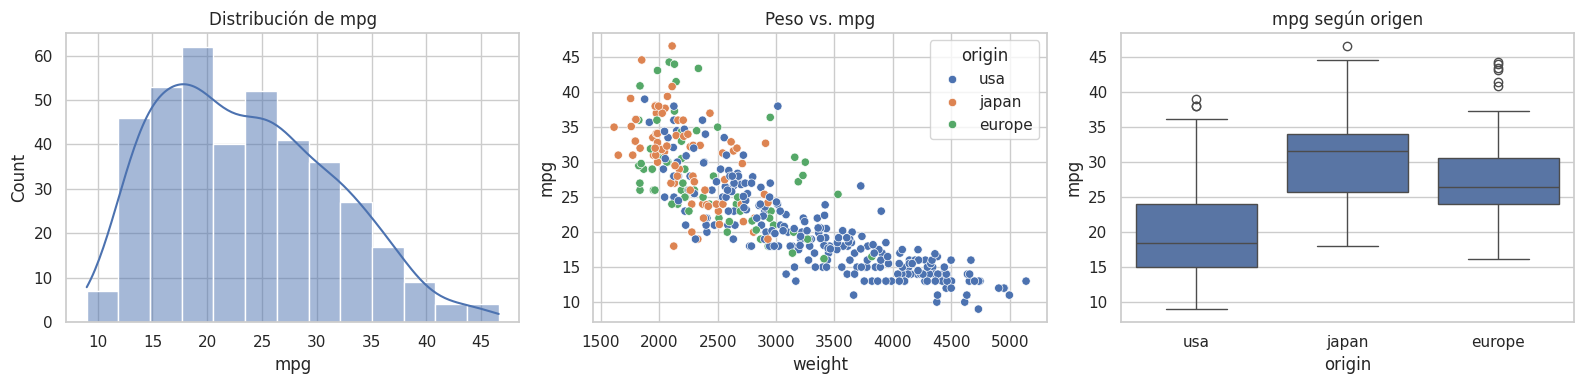

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

# 1) Distribución de la variable objetivo
sns.histplot(df_autos["mpg"], kde=True, ax=ejes[0])
ejes[0].set_title("Distribución de mpg")

# 2) Relación entre peso y consumo
sns.scatterplot(data=df_autos, x="weight", y="mpg", hue="origin", ax=ejes[1])
ejes[1].set_title("Peso vs. mpg")

# 3) mpg según origen del auto
sns.boxplot(data=df_autos, x="origin", y="mpg", ax=ejes[2])
ejes[2].set_title("mpg según origen")

plt.tight_layout()
plt.show()

### 🤔 Para pensar
- ¿Qué relación observás entre el peso del auto y su consumo? ¿Parece lineal?
- ¿Crees que el origen del auto aporta información útil?

1-
Hay una relación negativa clara: a mayor peso, menos millas por galón, es decir, más consumo. No es del todo lineal: en autos livianos el mpg cae rápido al aumentar el peso, y en los pesados la caída se aplana, formando una leve curva. Una recta la aproxima bien, pero un modelo no lineal puede capturarla mejor.

2-
Sí: en el boxplot los autos japoneses y europeos tienen una mediana de mpg más alta que los estadounidenses. Pero parte de esa información se superpone con el peso, porque los autos de EE.UU. suelen ser más pesados

--------

## Paso 1: separar variables y dividir en entrenamiento / prueba

- **X**: variables predictoras (características del auto). Quitamos `name` porque es un identificador, no una característica útil.
- **y**: variable objetivo (`mpg`).

Dividimos en:
- **Entrenamiento (80 %)**: con estos datos la red aprende.
- **Prueba (20 %)**: los guardamos "bajo llave" para evaluar al final. ⚠️ **No se tocan** hasta la evaluación final: simulan datos nuevos que el modelo nunca vio.

In [ ]:
# Separamos predictoras (X) y objetivo (y)
X = df_autos.drop(columns=["mpg", "name"])
y = df_autos["mpg"]

# Dividimos en entrenamiento y prueba
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

print(f"Entrenamiento: {X_ent.shape[0]} autos")
print(f"Prueba:        {X_prueba.shape[0]} autos")

Entrenamiento: 318 autos
Prueba:        80 autos


## Paso 2. Modelos de referencia (*baselines*)

Antes de entrenar una red neuronal, siempre conviene tener **modelos simples para comparar**. Si la red no le gana a un modelo simple, no vale la pena la complejidad.

Vamos a usar dos:
- **Dummy**: predice siempre el promedio de `mpg` (el modelo más "tonto" posible).
- **Regresión lineal**: un modelo simple y muy usado.

Primero definimos **cómo preparar los datos** (el "preprocesador") y una función para evaluar modelos.

### Preprocesamiento: ¡clave para las redes neuronales!

Las redes neuronales son **muy sensibles a la escala** de las variables. Por ejemplo, `weight` está en miles (≈ 3000) y `cylinders` entre 3 y 8. Si no las escalamos, la red aprende mal.

Necesitamos:
1. **Imputar** valores faltantes (con la mediana en variables numéricas).
2. **Estandarizar** las numéricas (`StandardScaler`: media 0 y desvío 1).
3. **Codificar** las categóricas como columnas 0/1 (`OneHotEncoder`), porque la red solo entiende números.

Todo esto lo empaquetamos en un `ColumnTransformer`. Lo bueno: al meterlo dentro de un `Pipeline`, el preprocesamiento se **ajusta solo con los datos de entrenamiento** y se aplica automáticamente a los de prueba (evitando "filtrar" información de prueba, lo que se llama *data leakage*).

In [ ]:
# Separamos las columnas según su tipo
cols_num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cols_cat = ["origin"]

# Preprocesador: qué hacerle a cada grupo de columnas
preprocesador_reg = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),   # rellena faltantes con la mediana
        ("escalar", StandardScaler())                    # media 0, desvío 1
    ]), cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat)  # categorías -> columnas 0/1
])

preprocesador_reg

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['cylinders', 'displacement', 'horsepower',
                                  'weight', 'acceleration', 'model_year']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['origin'])])

In [ ]:
# Función para evaluar un modelo de regresión de forma ordenada
def evaluar_regresion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "RMSE_entrenamiento": root_mean_squared_error(y_ent, pred_ent),
        "RMSE_prueba": root_mean_squared_error(y_prueba, pred_prueba),
        "MAE_prueba": mean_absolute_error(y_prueba, pred_prueba),
        "R2_prueba": r2_score(y_prueba, pred_prueba),
    }

# Aquí iremos guardando los resultados de cada modelo para compararlos al final
resultados_reg = []

In [ ]:
# Baseline 1: predice siempre el promedio
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_ent[cols_num], y_ent)
resultados_reg.append(evaluar_regresion(modelo_dummy, X_ent[cols_num], y_ent, X_prueba[cols_num], y_prueba, "Dummy (promedio)"))

# Baseline 2: regresión lineal (dentro de un Pipeline con el mismo preprocesador)
modelo_lineal = Pipeline([
    ("prep", preprocesador_reg),
    ("modelo", LinearRegression())
])
modelo_lineal.fit(X_ent, y_ent)
resultados_reg.append(evaluar_regresion(modelo_lineal, X_ent, y_ent, X_prueba, y_prueba, "Regresión lineal"))

pd.DataFrame(resultados_reg)

,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),7.918,7.347,5.955,-0.004
1,Regresión lineal,3.370,2.888,2.288,0.845


### 📏 ¿Cómo leer las métricas de regresión?

- **RMSE** (raíz del error cuadrático medio): error típico de la predicción, **en las mismas unidades que `mpg`**. Penaliza más los errores grandes. *Menor es mejor.*
- **MAE** (error absoluto medio): promedio de cuánto nos equivocamos, en unidades de `mpg`. *Menor es mejor.*
- **R²**: proporción de la variabilidad de `y` que el modelo explica. 1 = perfecto, 0 = igual que predecir el promedio. *Mayor es mejor.*

Fijate también en la diferencia entre **RMSE de entrenamiento y de prueba**: si en entrenamiento es mucho menor, hay señales de **sobreajuste** (el modelo "memorizó" en lugar de aprender).

## Paso 3 ¿Por qué hay que escalar? Una demostración

Veamos con nuestros propios ojos qué pasa si entrenamos la red **sin estandarizar** las variables (solo imputamos los faltantes) y lo comparamos con la red **con escalado**.

Como los pesos iniciales son aleatorios, repetimos el experimento con **5 semillas distintas** (una sola corrida podría engañarnos).

In [ ]:
r2_sin_escalar, r2_con_escalado = [], []

for semilla in range(5):
    # (a) Red SIN escalar: solo variables numéricas, imputadas
    sin_escalar = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=semilla))
    ]).fit(X_ent[cols_num], y_ent)
    r2_sin_escalar.append(r2_score(y_prueba, sin_escalar.predict(X_prueba[cols_num])))

    # (b) Red CON escalado: usamos nuestro preprocesador completo
    con_escalado = Pipeline([
        ("prep", preprocesador_reg),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=semilla))
    ]).fit(X_ent, y_ent)
    r2_con_escalado.append(r2_score(y_prueba, con_escalado.predict(X_prueba)))

demo_escalado = pd.DataFrame({
    "semilla": range(5),
    "R2 sin escalar": r2_sin_escalar,
    "R2 con escalado": r2_con_escalado
})
demo_escalado

,semilla,R2 sin escalar,R2 con escalado
0,0,-3.391,0.898
1,1,0.796,0.903
2,2,-1.308,0.905
3,3,0.891,0.912
4,4,-72.231,0.909


> 💡 **Lección:** sin escalar, la red puede **divergir** (R² muy negativo: ¡peor que predecir siempre el promedio!) o depender de la suerte de la semilla. Con variables estandarizadas, el entrenamiento es **estable** y los resultados son buenos y consistentes. Por eso el escalado es **obligatorio** en redes neuronales.

## Paso 4: nuestra primera red neuronal para regresión

Armamos un `Pipeline` con dos pasos:
1. `prep`: el preprocesador que definimos.
2. `mlp`: la red neuronal `MLPRegressor`.

Usamos `hidden_layer_sizes=(64, 32)`: dos capas ocultas, la primera con 64 neuronas y la segunda con 32.

In [ ]:
# Definimos la red neuronal dentro de un Pipeline
mlp_reg = Pipeline([
    ("prep", preprocesador_reg),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(64, 32),   # 2 capas ocultas: 64 y 32 neuronas
        activation="relu",             # función de activación
        max_iter=2000,                 # máximo de épocas
        random_state=SEMILLA           # semilla para reproducibilidad
    ))
])

# Entrenamos ("fit") con los datos de entrenamiento
mlp_reg.fit(X_ent, y_ent)

# ¿Cuántas épocas usó realmente la red? (si es igual a max_iter, llegó al límite)
print("Épocas realizadas:", mlp_reg.named_steps["mlp"].n_iter_)

# Evaluamos y guardamos resultados
resultados_reg.append(evaluar_regresion(mlp_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP inicial (64,32)"))
pd.DataFrame(resultados_reg)

Épocas realizadas: 2000


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),7.918,7.347,5.955,-0.004
1,Regresión lineal,3.370,2.888,2.288,0.845
2,"MLP inicial (64,32)",1.745,2.427,1.763,0.890


## Paso 5 · Analizar los resultados

Los números solos no cuentan toda la historia. Miremos **tres gráficos** muy útiles:

1. **Curva de pérdida**: cómo baja el error durante el entrenamiento. Debería descender y estabilizarse.
2. **Real vs. predicho**: si el modelo fuera perfecto, todos los puntos estarían sobre la diagonal.
3. **Residuos** (real − predicho): deberían estar centrados en 0 y sin patrones marcados.

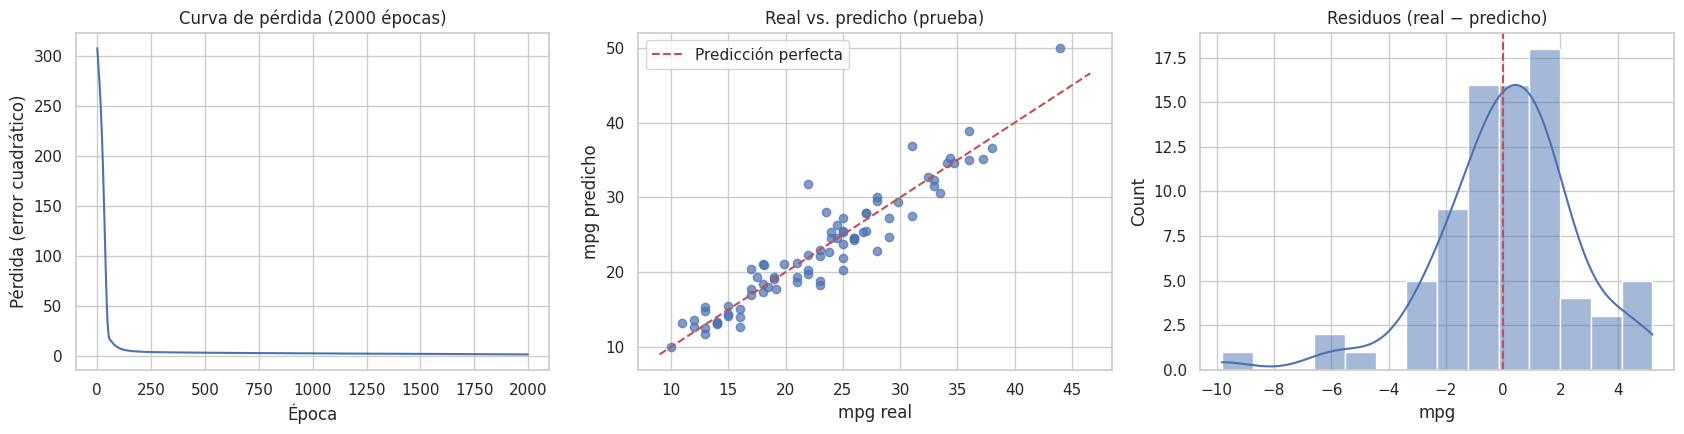

In [ ]:
# Obtenemos el objeto MLP que está dentro del Pipeline
red = mlp_reg.named_steps["mlp"]
pred_prueba = mlp_reg.predict(X_prueba)
residuos = y_prueba - pred_prueba

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Curva de pérdida durante el entrenamiento
ejes[0].plot(red.loss_curve_)
ejes[0].set_title(f"Curva de pérdida ({red.n_iter_} épocas)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida (error cuadrático)")

# 2) Real vs predicho
ejes[1].scatter(y_prueba, pred_prueba, alpha=0.7)
lim = [y.min(), y.max()]
ejes[1].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[1].set_title("Real vs. predicho (prueba)")
ejes[1].set_xlabel("mpg real")
ejes[1].set_ylabel("mpg predicho")
ejes[1].legend()

# 3) Histograma de residuos
sns.histplot(residuos, kde=True, ax=ejes[2])
ejes[2].axvline(0, color="r", linestyle="--")
ejes[2].set_title("Residuos (real − predicho)")

plt.tight_layout()
plt.show()

### 🤔 Para pensar
- ¿La curva de pérdida se estabilizó, o el entrenamiento terminó "a la fuerza" por `max_iter`? (Mirá el número de épocas en el título del gráfico.)
- ¿En qué rango de `mpg` se equivoca más el modelo?

1-
Terminó a la fuerza: el título muestra 2000 épocas, igual al max_iter. Aunque la curva cae fuerte al inicio y después queda casi plana, el modelo cortó por llegar al límite y no porque convergió. Habría que subir max_iter y verificar que n_iter_ quede por debajo del tope.

2-
Por debajo de 20 mpg (autos de alto consumo) los puntos están muy pegados a la diagonal. A partir de ~20 mpg la dispersión crece, y ahí están los errores más grandes: un auto de 22 mpg predicho en ~32 y otro de 44 predicho en ~50. Varios de esos errores son sobreestimaciones, que explican la cola izquierda del histograma de residuos (hasta −10).


## Paso 6 · Un detalle importante: la aleatoriedad

Los **pesos iniciales** de la red se eligen al azar. Eso significa que **dos entrenamientos con distinta semilla pueden dar resultados distintos**, aunque los datos y la configuración sean idénticos.

Veamos cuánto varía el resultado entrenando la misma red con 10 semillas diferentes:

R² en prueba con 10 semillas distintas:
[0.873 0.891 0.895 0.902 0.89  0.886 0.891 0.879 0.878 0.882]

Promedio: 0.887  |  Desvío: 0.008
Mínimo:   0.873  |  Máximo: 0.902


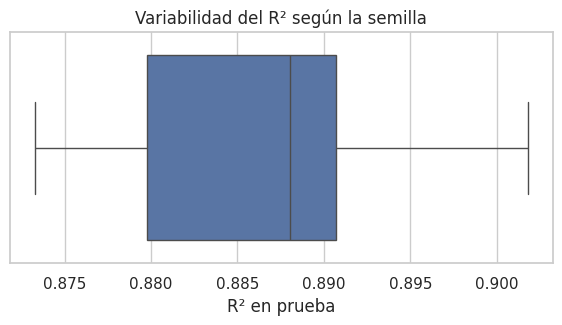

In [ ]:
r2_por_semilla = []

for semilla in range(10):
    modelo = clone(mlp_reg)                        # copia "limpia" del pipeline
    modelo.set_params(mlp__random_state=semilla)   # cambiamos solo la semilla de la red
    modelo.fit(X_ent, y_ent)
    r2_por_semilla.append(r2_score(y_prueba, modelo.predict(X_prueba)))

print("R² en prueba con 10 semillas distintas:")
print(np.round(r2_por_semilla, 3))
print(f"\nPromedio: {np.mean(r2_por_semilla):.3f}  |  Desvío: {np.std(r2_por_semilla):.3f}")
print(f"Mínimo:   {np.min(r2_por_semilla):.3f}  |  Máximo: {np.max(r2_por_semilla):.3f}")

plt.figure(figsize=(7, 3))
sns.boxplot(x=r2_por_semilla)
plt.title("Variabilidad del R² según la semilla")
plt.xlabel("R² en prueba")
plt.show()

> 💡 **Lección:** una diferencia pequeña entre dos configuraciones puede ser **puro azar**. Por eso es importante usar **validación cruzada** (que promedia varias evaluaciones) para comparar modelos, en lugar de fiarnos de una sola corrida.

## Paso 7 · Explorando hiperparámetros "a mano"

Antes de automatizar la búsqueda, entendamos el efecto de algunos "botones".

### 7.1 · `max_iter`: ¿y si cortamos el entrenamiento muy pronto?

Si la red no tiene tiempo suficiente para converger, `scikit-learn` nos avisa con un `ConvergenceWarning`:

In [ ]:
# Entrenamos con solo 20 épocas: ¡muy poco!
mlp_corto = clone(mlp_reg)
mlp_corto.set_params(mlp__max_iter=20)

# Reactivamos (solo dentro de este bloque) los avisos de convergencia que habíamos ocultado
with warnings.catch_warnings():
    warnings.simplefilter("always", ConvergenceWarning)
    mlp_corto.fit(X_ent, y_ent)   # <- verás una advertencia de convergencia

print(f"R² en prueba con 20 épocas:   {r2_score(y_prueba, mlp_corto.predict(X_prueba)):.3f}")
#print(f"R² en prueba con 2000 épocas: {r2_score(y_prueba, mlp_reg.predict(X_prueba)):.3f}")

R² en prueba con 20 épocas:   -7.037


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


> ⚠️ **Si ves un `ConvergenceWarning`**: la red no terminó de aprender. Aumentá `max_iter`, o revisá que las variables estén escaladas.
>
> Al inicio del notebook ocultamos estos avisos para no llenar la pantalla, pero **no dejes de vigilar** cuántas épocas usa tu red: se consulta con `red.n_iter_` (si es igual a `max_iter`, el entrenamiento terminó por el límite y no porque convergió).

### 7.2 · `hidden_layer_sizes`: ¿cuántas neuronas necesitamos?

Usaremos una **curva de validación**: entrenamos redes de una capa con distinta cantidad de neuronas y medimos el R² tanto en entrenamiento como en validación cruzada (5 particiones del conjunto de entrenamiento).

- Pocas neuronas → el modelo es demasiado simple (**subajuste**).
- Muchas neuronas → puede volverse demasiado complejo (**sobreajuste**).

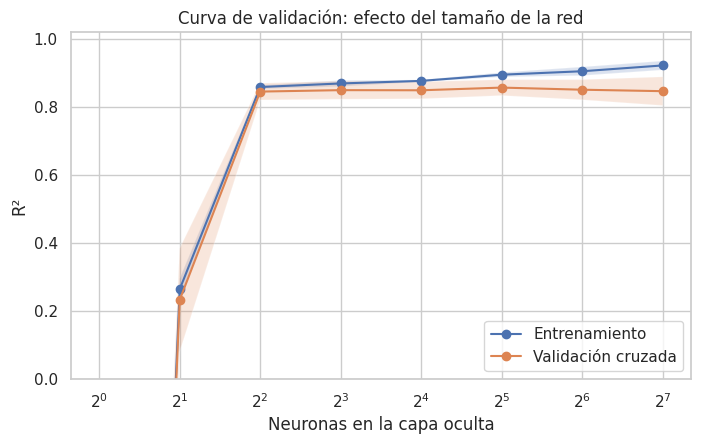

In [ ]:
# Probamos redes de una capa con distinta cantidad de neuronas
neuronas = [1, 2, 4, 8, 16, 32, 64, 128]
arquitecturas = [(n,) for n in neuronas]

puntaje_ent, puntaje_val = validation_curve(
    mlp_reg, X_ent, y_ent,
    param_name="mlp__hidden_layer_sizes",
    param_range=arquitecturas,
    cv=5, scoring="r2", n_jobs=-1
)

# Graficamos promedio ± desvío
plt.figure(figsize=(8, 4.5))
for puntajes, etiqueta in [(puntaje_ent, "Entrenamiento"), (puntaje_val, "Validación cruzada")]:
    media, desvio = puntajes.mean(axis=1), puntajes.std(axis=1)
    plt.plot(neuronas, media, marker="o", label=etiqueta)
    plt.fill_between(neuronas, media - desvio, media + desvio, alpha=0.2)

plt.xscale("log", base=2)
plt.xlabel("Neuronas en la capa oculta")
plt.ylabel("R²")
plt.title("Curva de validación: efecto del tamaño de la red")
plt.ylim(0, 1.02)
plt.legend()
plt.show()

### 🤔 Para pensar
- ¿A partir de cuántas neuronas deja de mejorar el R² de validación?
- ¿Hay una brecha entre la curva de entrenamiento y la de validación? ¿Qué nos dice eso?

1-
A partir de 4 neuronas. Con 1 y 2 el R² es muy bajo (subajuste: la red es demasiado simple). Con 4 salta a ~0.85 en validación y de ahí en adelante se mantiene prácticamente igual hasta 128. Agregar más neuronas no mejora la capacidad de generalizar.

2-
Hasta 16 neuronas las dos curvas van casi juntas, así que el modelo generaliza bien. Desde 32 neuronas el R² de entrenamiento sigue subiendo (hasta ~0.92) mientras el de validación queda plano o baja levemente. Esa brecha creciente indica el comienzo del sobreajuste: las neuronas extra sirven para memorizar el train, no para predecir mejor datos nuevos. Conviene elegir una red chica (4 a 16 neuronas).


## Paso 8: búsqueda automática de hiperparámetros: `GridSearchCV`

Probar combinaciones a mano es lento y poco riguroso. `GridSearchCV` hace esto por nosotros:

1. Definimos una **grilla** con los valores a probar para cada hiperparámetro.
2. Para **cada combinación**, entrena y evalúa con **validación cruzada** (aquí, 5 particiones).
3. Nos dice cuál fue la mejor y **reentrena** el mejor modelo con todo el conjunto de entrenamiento.

> ⚠️ Toda la búsqueda usa **solo los datos de entrenamiento**. El conjunto de prueba sigue intacto.

Nota: dentro de un `Pipeline`, los hiperparámetros se nombran como `paso__parametro` (con **doble guion bajo**), por ejemplo `mlp__alpha`.

Nuestra grilla tiene 3 × 3 × 2 = **18 combinaciones**, y con 5 particiones son 90 entrenamientos. Puede tardar 1-2 minutos. ☕

In [ ]:
# Grilla de hiperparámetros a explorar
grilla_reg = {
    "mlp__hidden_layer_sizes": [(16,), (64,), (64, 32)],   # arquitecturas
    "mlp__alpha": [0.0001, 0.01, 1.0],                     # regularización
    "mlp__learning_rate_init": [0.001, 0.01],              # tamaño de paso
}

busqueda_reg = GridSearchCV(
    estimator=mlp_reg,
    param_grid=grilla_reg,
    cv=5,                                     # validación cruzada de 5 particiones
    scoring="neg_root_mean_squared_error",    # sklearn maximiza: usamos -RMSE
    n_jobs=-1,                                # usa todos los núcleos disponibles
    verbose=1
)

busqueda_reg.fit(X_ent, y_ent)

print("\nMejores hiperparámetros:")
print(busqueda_reg.best_params_)
print(f"\nMejor RMSE en validación cruzada: {-busqueda_reg.best_score_:.3f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Mejores hiperparámetros:
{'mlp__alpha': 1.0, 'mlp__hidden_layer_sizes': (64,), 'mlp__learning_rate_init': 0.01}

Mejor RMSE en validación cruzada: 2.877


### Mirando todos los resultados de la búsqueda

`cv_results_` guarda lo que pasó con **cada** combinación. Conviene convertirlo en una tabla y ordenarlo. Prestá atención a la columna `std_test_score`: si el desvío es grande comparado con las diferencias entre modelos, esas diferencias **no son concluyentes**.

In [ ]:
res = pd.DataFrame(busqueda_reg.cv_results_)
res["RMSE_cv"] = -res["mean_test_score"]     # volvemos a un RMSE positivo

columnas = ["param_mlp__hidden_layer_sizes", "param_mlp__alpha", "param_mlp__learning_rate_init",
            "RMSE_cv", "std_test_score", "rank_test_score"]

res.sort_values("rank_test_score")[columnas].head(8)

,param_mlp__hidden_layer_sizes,param_mlp__alpha,param_mlp__learning_rate_init,RMSE_cv,std_test_score,rank_test_score
15,"(64,)",1.000e+00,0.010,2.877,0.330,1
16,"(64, 32)",1.000e+00,0.001,2.953,0.228,2
10,"(64, 32)",1.000e-02,0.001,2.973,0.267,3
4,"(64, 32)",1.000e-04,0.001,2.974,0.239,4
17,"(64, 32)",1.000e+00,0.010,2.982,0.335,5
14,"(64,)",1.000e+00,0.001,3.011,0.344,6
9,"(64,)",1.000e-02,0.010,3.013,0.257,7
12,"(16,)",1.000e+00,0.001,3.020,0.303,8


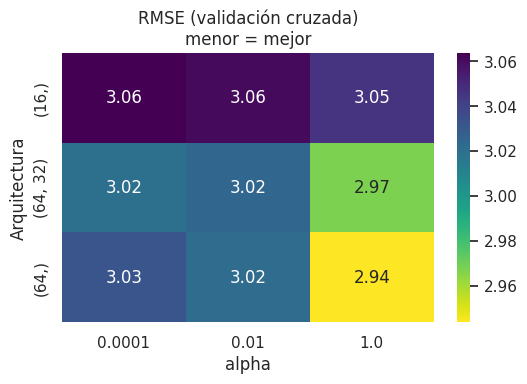

In [ ]:
# Visualizamos: RMSE promedio según arquitectura y alpha (promediando sobre learning rate)
res["arquitectura"] = res["param_mlp__hidden_layer_sizes"].astype(str)
tabla = res.pivot_table(index="arquitectura", columns="param_mlp__alpha", values="RMSE_cv", aggfunc="mean")

plt.figure(figsize=(6, 3.5))
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="viridis_r")
plt.title("RMSE (validación cruzada)\nmenor = mejor")
plt.xlabel("alpha")
plt.ylabel("Arquitectura")
plt.show()

## Paso 9 · Evaluación final en el conjunto de prueba

Ahora sí, usamos por **única vez** el conjunto de prueba para evaluar el mejor modelo encontrado. Lo tenemos en `busqueda_reg.best_estimator_` (ya reentrenado con todo el conjunto de entrenamiento).

In [ ]:
mejor_reg = busqueda_reg.best_estimator_

resultados_reg.append(evaluar_regresion(mejor_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP optimizado (GridSearch)"))

tabla_final_reg = pd.DataFrame(resultados_reg).set_index("modelo")
tabla_final_reg

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Dummy (promedio),7.918,7.347,5.955,-0.004
Regresión lineal,3.370,2.888,2.288,0.845
"MLP inicial (64,32)",1.745,2.427,1.763,0.890
MLP optimizado (GridSearch),2.176,2.404,1.796,0.893


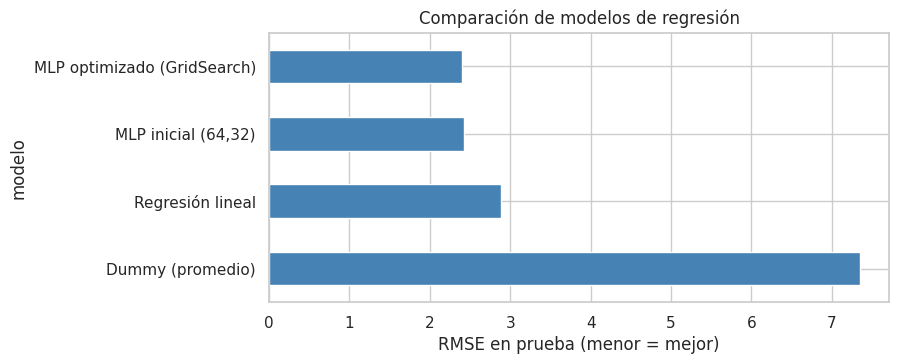

In [ ]:
# Comparamos gráficamente el RMSE en prueba de todos los modelos
tabla_final_reg["RMSE_prueba"].plot(kind="barh", figsize=(8, 3.5), color="steelblue")
plt.xlabel("RMSE en prueba (menor = mejor)")
plt.title("Comparación de modelos de regresión")
plt.show()

## Paso 10. Abriendo un poco la caja negra: importancia por permutación

Aunque la red es una "caja negra", podemos preguntarle **qué variables le importan**. La **importancia por permutación** funciona así:

1. Tomamos los datos de prueba y **mezclamos al azar** los valores de **una** variable.
2. Medimos cuánto **empeora** el error del modelo.
3. Si empeora mucho → esa variable era **importante**. Si casi no cambia → no aportaba.

Como usamos el `Pipeline` completo, la importancia se calcula sobre las **variables originales** (por ejemplo `origin` completo, no cada columna 0/1).

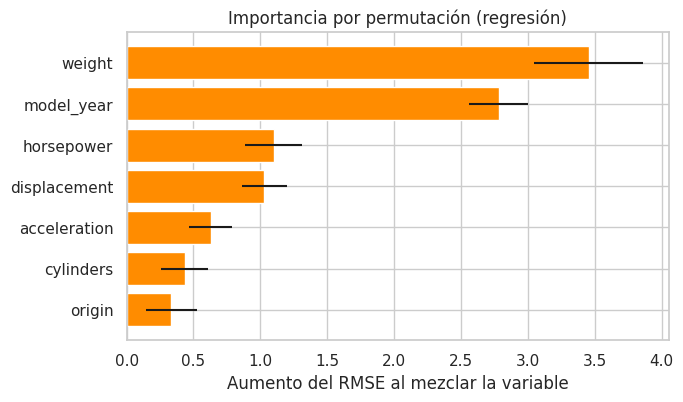

In [ ]:
imp = permutation_importance(
    mejor_reg, X_prueba, y_prueba,
    n_repeats=20,                              # repetimos el mezclado 20 veces
    scoring="neg_root_mean_squared_error",
    random_state=SEMILLA
)

importancias = pd.DataFrame({
    "variable": X_prueba.columns,
    "aumento_RMSE": imp.importances_mean,      # cuánto empeora el RMSE al mezclar la variable
    "desvio": imp.importances_std
}).sort_values("aumento_RMSE")

plt.figure(figsize=(7, 4))
plt.barh(importancias["variable"], importancias["aumento_RMSE"], xerr=importancias["desvio"], color="darkorange")
plt.xlabel("Aumento del RMSE al mezclar la variable")
plt.title("Importancia por permutación (regresión)")
plt.show()

### Usando el modelo en un caso nuevo

Una vez entrenado, el `Pipeline` funciona como una función: le pasamos un auto **con las columnas originales** y devuelve la predicción (el preprocesamiento se hace solo).

In [ ]:
# Un auto hipotético que no está en el dataset
auto_nuevo = pd.DataFrame([{
    "cylinders": 4, "displacement": 120, "horsepower": 85,
    "weight": 2300, "acceleration": 15, "model_year": 10, "origin": "japan"
}])

print(f"Consumo predicho: {mejor_reg.predict(auto_nuevo)[0]:.1f} mpg")

Consumo predicho: 119.4 mpg


---
# Parte 4. Resumen y buenas prácticas

## La receta que usamos (sirve para regresión y clasificación)

1. **Explorar** los datos (tipos, faltantes, distribuciones).
2. **Dividir** en entrenamiento y prueba (con `stratify` si es clasificación).
3. **Preprocesar dentro de un `Pipeline`**: imputar → escalar numéricas → codificar categóricas.
4. Entrenar **modelos de referencia** (Dummy, lineal/logístico) para tener con qué comparar.
5. Entrenar la **red neuronal** y **analizar resultados** (métricas, gráficos, errores).
6. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` / `RandomizedSearchCV`), usando **solo** el conjunto de entrenamiento.
7. **Evaluar una sola vez** en el conjunto de prueba.
8. **Interpretar** con importancia por permutación y **reportar** con honestidad (¡incluida la variabilidad!).

## ✅ Checklist rápido

| Situación | Qué hacer |
|---|---|
| `ConvergenceWarning` (o `n_iter_` igual a `max_iter`) | Aumentar `max_iter`, verificar que las variables estén escaladas, probar otro `solver` |
| Rendimiento muy bueno en entrenamiento y malo en prueba (sobreajuste) | Aumentar `alpha`, reducir neuronas, usar `early_stopping=True`, conseguir más datos |
| Rendimiento malo en ambos (subajuste) | Más neuronas/capas, más épocas, mejores variables |
| Resultados que cambian mucho entre corridas | Fijar `random_state`, comparar con validación cruzada, repetir con varias semillas |
| Dataset muy pequeño | Probar `solver="lbfgs"` |
| Clases desbalanceadas | No confiar solo en accuracy: mirar F1 macro, recall por clase y matriz de confusión |

## ⚖️ Ventajas y limitaciones de los MLP

** Ventajas:** capturan relaciones no lineales e interacciones complejas sin que las especifiquemos.

**Limitaciones:** son sensibles a la escala, tienen muchos hiperparámetros, son poco interpretables y suelen no superar a otros métodos (como bosques aleatorios o *gradient boosting*) en datos tabulares pequeños. ¡Siempre comparalos!

> `scikit-learn` es ideal para aprender y para problemas tabulares pequeños o medianos. Para redes profundas, imágenes, texto o mucho volumen de datos se usan librerías como **PyTorch** o **TensorFlow/Keras**.

---
# Parte 5 - Actividades

Ahora es tu turno. **Reutilizá el código de las partes anteriores** (copiar, pegar y adaptar es totalmente válido). Cada actividad indica qué parte del taller te sirve de guía.

> 💡 En las celdas de código encontrarás pistas como comentarios. Las celdas de texto "**Tu respuesta:**" son para que escribas tus conclusiones (doble clic para editar).

## Actividad 1. Regresión: predecir el precio de diamantes

**Dataset:** `diamonds` (público, repositorio de datos de `seaborn`). Cada fila es un diamante con su precio en dólares y características como peso (`carat`), calidad de corte (`cut`), color (`color`), claridad (`clarity`) y dimensiones (`x`, `y`, `z`).

**Objetivo:** predecir `price` con una red neuronal y compararla con modelos de referencia.

**Te sirve de guía:** Parte 2 (Regresión).

Para que los entrenamientos no tarden demasiado, trabajaremos con una **muestra de 3000 diamantes**.

#### 1.0 _ Setup Inicial

In [ ]:
# Cargamos el dataset y tomamos una muestra de 3000 filas
url_diamantes = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
df_diam = pd.read_csv(url_diamantes).sample(n=3000, random_state=SEMILLA).reset_index(drop=True)

df_diam.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
1,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
2,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
3,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
4,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


#### **1.1 · Exploración.** Averiguá: ¿cuántas variables numéricas y categóricas hay? ¿Hay valores faltantes? Graficá la distribución de `price` y la relación entre `carat` y `price`. ¿Notás algo particular en la distribución del precio?

In [ ]:
df_diam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    3000 non-null   float64
 1   cut      3000 non-null   object 
 2   color    3000 non-null   object 
 3   clarity  3000 non-null   object 
 4   depth    3000 non-null   float64
 5   table    3000 non-null   float64
 6   price    3000 non-null   int64  
 7   x        3000 non-null   float64
 8   y        3000 non-null   float64
 9   z        3000 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 234.5+ KB


In [ ]:
df_diam.describe()

,carat,depth,table,price,x,y,z
count,3000.000,3000.000,3000.000,3000.000,3000.000,3000.000,3000.000
mean,0.803,61.760,57.453,3946.290,5.735,5.735,3.541
std,0.490,1.432,2.288,4083.685,1.149,1.142,0.706
min,0.230,54.400,49.000,358.000,3.880,3.920,2.320
25%,0.390,61.075,56.000,926.750,4.680,4.690,2.890
50%,0.700,61.900,57.000,2352.000,5.690,5.700,3.520
75%,1.040,62.500,59.000,5303.250,6.560,6.560,4.030
max,4.010,69.900,73.000,18823.000,10.020,9.940,6.310


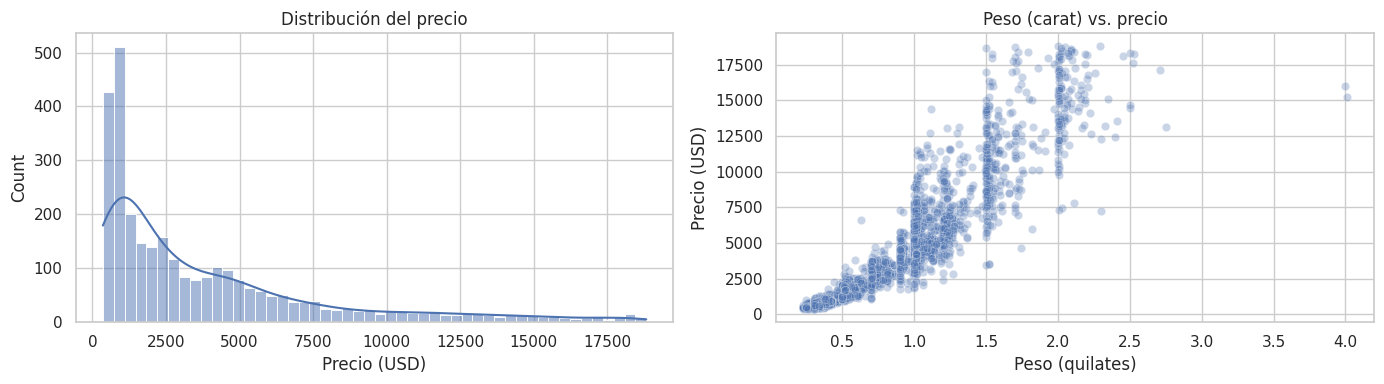

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

# Distribución del precio
sns.histplot(df_diam["price"], kde=True, bins=50, ax=ejes[0])
ejes[0].set_title("Distribución del precio")
ejes[0].set_xlabel("Precio (USD)")

# Relación entre peso y precio
sns.scatterplot(data=df_diam, x="carat", y="price", alpha=0.3, ax=ejes[1])
ejes[1].set_title("Peso (carat) vs. precio")
ejes[1].set_xlabel("Peso (quilates)")
ejes[1].set_ylabel("Precio (USD)")

plt.tight_layout()
plt.show()



---



**Composición del dataset**:
- 10 columnas totales: **6 numéricas** (`carat`, `depth`, `table`, `price`, `x`, `y`, `z`) y **3 categóricas** (`cut`, `color`, `clarity`).
- `price` es la variable objetivo (int64).
- 3000 filas, **sin valores faltantes**, no requiere imputación obligatoria.

**Distribución del precio**:
- Fuertemente **asimétrica a la derecha** (sesgo positivo): la mayoría de los diamantes están concentrados en precios bajos (< $5.000)


**Relación carat vs price**:
- Relación claramente **positiva y no lineal** (curva creciente). A mayor peso (quilates), mayor precio.
- La dispersión aumenta con el peso: diamantes grandes muestran mucha variación de precio para un mismo `carat`. Esto refleja que otras variables (calidad del corte, color, claridad) también influyen fuertemente en los diamantes caros.

---



#### **1.2 · División y preprocesamiento.**
- Separá `X` (todo menos `price`) e `y` (`price`).
- Dividí en entrenamiento (80 %) y prueba (20 %).
- Armá un `ColumnTransformer` que estandarice las numéricas y aplique `OneHotEncoder` a `cut`, `color` y `clarity`.

In [ ]:
# Preparacion del dataset
X = df_diam.drop(columns=["price"])
y= df_diam["price"]

# Se divide el set en train y test
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=SEMILLA)

# Se verifica tamaño
print(f"Entrenamiento: {X_train.shape[0]} diamantes")
print(f"Prueba:        {X_test.shape[0]} diamantes")

Entrenamiento: 2400 diamantes
Prueba:        600 diamantes


In [ ]:
# Se crea preprocesador
col_num = ["carat", "depth", "table",	"x",	"y",	"z"]
col_cat = ["cut",	"color",	"clarity"]

preprocesador = ColumnTransformer([
    ('num', Pipeline([
      ("imputar", SimpleImputer(strategy="median")),
      ("escalar", StandardScaler())
    ]), col_num),

    ("cat", OneHotEncoder(handle_unknown="ignore"), col_cat)

])

preprocesador

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['carat', 'depth', 'table', 'x', 'y', 'z']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['cut', 'color', 'clarity'])])

#### **1.3 · Modelos de referencia.** Entrená un `DummyRegressor` y una `LinearRegression`, y guardá sus métricas (RMSE, MAE, R²) en una lista de resultados usando la función `evaluar_regresion` que ya definimos.

In [ ]:
resultados_diam = []

In [ ]:
# Modelo Baseline - Se entrena modelo DummyRegressor utilizando la funcion evaluar_regresion ya definida
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_train[col_num], y_train)
resultados_diam.append(evaluar_regresion(modelo_dummy, X_train[col_num], y_train, X_test[col_num], y_test, "Dummy (promedio)"))


In [ ]:
# Modelo de regresion lineal utilizando la funcion evaluar_regresion ya definida
modelo_lineal = Pipeline([
    ("prep", preprocesador),
    ("modelo", LinearRegression())
])
modelo_lineal.fit(X_train, y_train)
resultados_diam.append(evaluar_regresion(modelo_lineal, X_train, y_train, X_test, y_test, "Regresión lineal"))

pd.DataFrame(resultados_diam)

,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932


#### **1.4 · Primera red neuronal.** Entrená un `MLPRegressor` con `hidden_layer_sizes=(64, 32)` dentro de un `Pipeline`. Evaluá en entrenamiento y prueba. Graficá **real vs. predicho** y la **curva de pérdida**. ¿Le gana a la regresión lineal?

In [ ]:
# Definimos la red neuronal dentro de un Pipeline
mlp_reg_diam = Pipeline([
    ("prep", preprocesador),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(64, 32),   # 2 capas ocultas: 64 y 32 neuronas
        activation="relu",             # función de activación
        max_iter=3000,                 # máximo de épocas
        random_state=SEMILLA           # semilla para reproducibilidad
    ))
])


mlp_reg_diam.fit(X_train, y_train)

# Cuántas épocas usó realmente la red
print("Épocas realizadas:", mlp_reg_diam.named_steps["mlp"].n_iter_)

# Evaluamos y guardamos resultados
resultados_diam.append(evaluar_regresion(mlp_reg_diam, X_train, y_train, X_test, y_test, "MLP inicial (64,32)"))
pd.DataFrame(resultados_diam)

Épocas realizadas: 2097


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932
2,"MLP inicial (64,32)",582.645,592.220,332.442,0.981


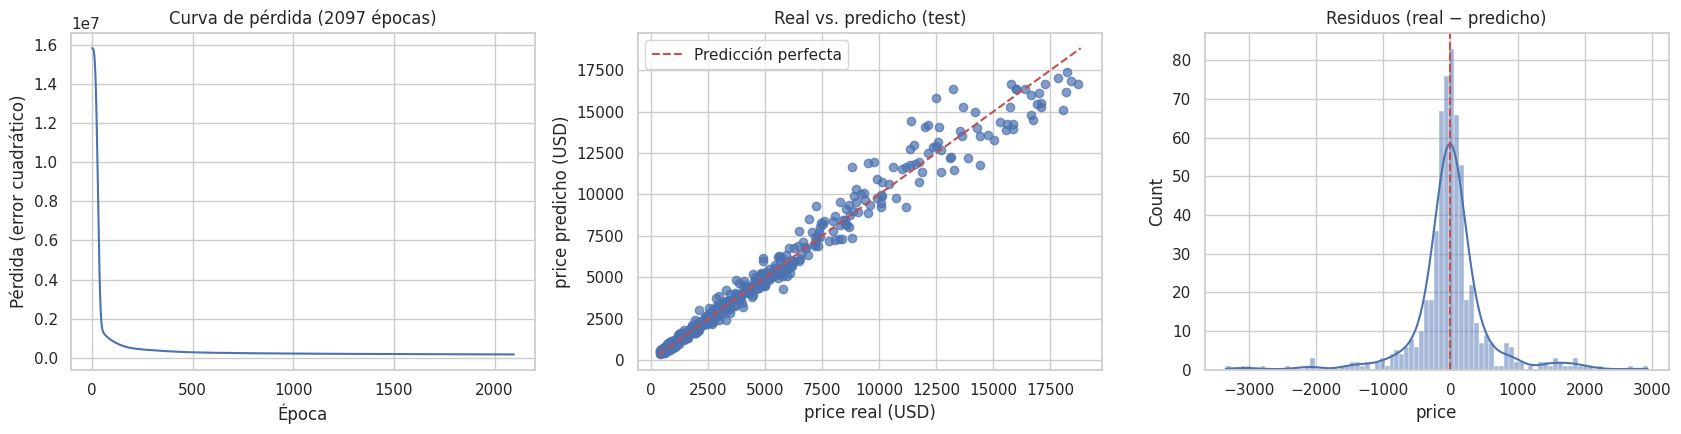

In [ ]:
# Obtenemos el objeto MLP que está dentro del Pipeline
red = mlp_reg_diam.named_steps["mlp"]
pred_test = mlp_reg_diam.predict(X_test)
residuos = y_test - pred_test

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Curva de pérdida durante el entrenamiento
ejes[0].plot(red.loss_curve_)
ejes[0].set_title(f"Curva de pérdida ({red.n_iter_} épocas)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida (error cuadrático)")

# 2) Real vs predicho
ejes[1].scatter(y_test, pred_test, alpha=0.7)
lim = [y.min(), y.max()]
ejes[1].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[1].set_title("Real vs. predicho (test)")
ejes[1].set_xlabel("price real (USD)")
ejes[1].set_ylabel("price predicho (USD)")
ejes[1].legend()

# 3) Histograma de residuos
sns.histplot(residuos, kde=True, ax=ejes[2])
ejes[2].axvline(0, color="r", linestyle="--")
ejes[2].set_title("Residuos (real − predicho)")

plt.tight_layout()
plt.show()

#### **1.5 · Ajuste de hiperparámetros.** Usá `GridSearchCV` o `RandomizedSearchCV` (a tu elección) con validación cruzada de 5 particiones para explorar al menos **3 hiperparámetros** (por ejemplo `hidden_layer_sizes`, `alpha`, `learning_rate_init`). Mostrá los 5 mejores resultados y evaluá el mejor modelo en el conjunto de prueba.

⏱️ *Cuidado con el tiempo de ejecución: empezá con una grilla chica.*

In [ ]:
grilla_diam = {
    "mlp__hidden_layer_sizes": [(16,), (64,), (64, 32)],     # 3 arquitecturas
    "mlp__alpha": [0.0001, 0.01, 1.0],                       # 3 valores de regularización
    "mlp__learning_rate_init": [0.001, 0.01],                # 2 learning rates
}


In [ ]:
busqueda_diam = GridSearchCV(
    estimator=mlp_reg_diam,                        # pipeline MLP ya definido
    param_grid=grilla_diam,
    cv=5,
    scoring="neg_root_mean_squared_error",         # sklearn maximiza → usa negativo
    n_jobs=-1,                                     # paraleliza en todos los cores
    verbose=1                                      # muestra progreso
)

busqueda_diam.fit(X_train, y_train)

print("\nMejores hiperparámetros:")
print(busqueda_diam.best_params_)
print(f"\nMejor RMSE en CV: {-busqueda_diam.best_score_:.3f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Mejores hiperparámetros:
{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (16,), 'mlp__learning_rate_init': 0.01}

Mejor RMSE en CV: 657.635


In [ ]:
res = pd.DataFrame(busqueda_diam.cv_results_)
res["RMSE_cv"] = -res["mean_test_score"]

columnas = ["param_mlp__hidden_layer_sizes", "param_mlp__alpha", "param_mlp__learning_rate_init",
            "RMSE_cv", "std_test_score", "rank_test_score"]

res.sort_values("rank_test_score")[columnas].head(5)

,param_mlp__hidden_layer_sizes,param_mlp__alpha,param_mlp__learning_rate_init,RMSE_cv,std_test_score,rank_test_score
1,"(16,)",1.000e-04,0.010,657.635,67.382,1
16,"(64, 32)",1.000e+00,0.001,665.059,71.821,2
5,"(64, 32)",1.000e-04,0.010,665.146,64.481,3
7,"(16,)",1.000e-02,0.010,668.277,59.250,4
4,"(64, 32)",1.000e-04,0.001,668.931,54.076,5


In [ ]:
mejor_diam = busqueda_diam.best_estimator_

resultados_diam.append(evaluar_regresion(
    mejor_diam, X_train, y_train, X_test, y_test, "MLP optimizado (GridSearch)"
))

tabla_final = pd.DataFrame(resultados_diam).set_index("modelo")
tabla_final

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Dummy (promedio),4040.451,4249.481,3220.319,-0.001
Regresión lineal,1138.336,1106.483,730.659,0.932
"MLP inicial (64,32)",582.645,592.220,332.442,0.981
MLP optimizado (GridSearch),572.630,599.254,341.757,0.980


In [ ]:
print("Épocas del mejor:", mejor_diam.named_steps["mlp"].n_iter_)

Épocas del mejor: 2461


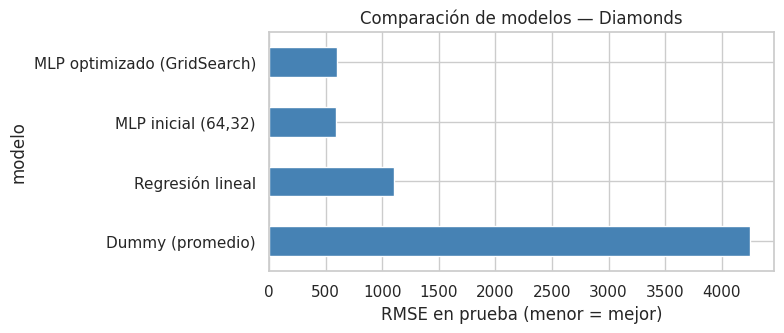

In [ ]:
pd.DataFrame(resultados_diam).set_index("modelo")["RMSE_prueba"].plot(
    kind="barh", figsize=(8, 3.5), color="steelblue"
)
plt.xlabel("RMSE en prueba (menor = mejor)")
plt.title("Comparación de modelos — Diamonds")
plt.tight_layout()
plt.show()

A pesar de evaluar 18 combinaciones con 5-fold CV (90 entrenamientos), el MLP optimizado por GridSearch resultó **marginalmente peor** en test (R²=0.980 vs 0.981 del MLP inicial).

La arquitectura ganadora `(16,)` sugiere que `(64, 32)` tiene capacidad excesiva para este problema. En producción, el MLP inicial con hiperparámetros default sería la elección más eficiente.

#### **1.6 · Interpretación.** Calculá la importancia por permutación del mejor modelo y graficala. ¿Qué variables son más importantes? ¿Coincide con lo que esperabas?

In [ ]:
imp_diam = permutation_importance(
    mejor_diam, X_test, y_test,
    n_repeats=20,                                # 20 permutaciones por feature para estabilidad
    scoring="neg_root_mean_squared_error",
    random_state=SEMILLA,
    n_jobs=-1                                    # paraleliza
)

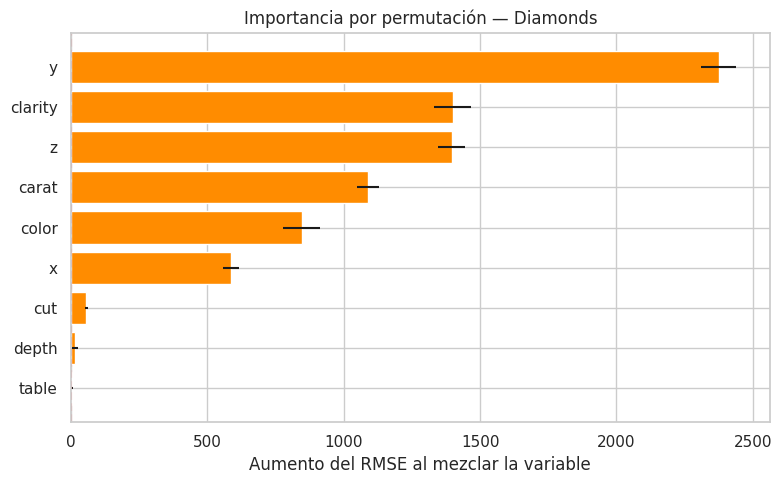

,variable,aumento_RMSE,desvio
7,y,2374.159,65.845
3,clarity,1399.550,67.133
8,z,1395.377,48.249
0,carat,1089.016,40.740
2,color,845.717,68.101
6,x,586.709,27.918
1,cut,56.595,6.631
4,depth,16.195,10.630
5,table,3.939,3.449


In [ ]:
importancias_diam = pd.DataFrame({
    "variable": X_test.columns,
    "aumento_RMSE": imp_diam.importances_mean,
    "desvio": imp_diam.importances_std
}).sort_values("aumento_RMSE")                   # ordenado para gráfico

plt.figure(figsize=(8, 5))
plt.barh(importancias_diam["variable"],
         importancias_diam["aumento_RMSE"],
         xerr=importancias_diam["desvio"],
         color="darkorange")
plt.xlabel("Aumento del RMSE al mezclar la variable")
plt.title("Importancia por permutación — Diamonds")
plt.axvline(0, color='red', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

importancias_diam.sort_values("aumento_RMSE", ascending=False)


Las variables más importantes para el modelo son `y` (dimensión en mm),
`clarity`, `z` y `carat`, todas con aumentos de RMSE > 1000 al permutarlas.
Esto es consistente con el conocimiento del dominio: el tamaño del diamante
(reflejado en `y`, `z`, `carat`, `x`) y la claridad son los principales
drivers del precio.

**Observación crítica**: `y` aparece como la feature más importante (RMSE +2374),
por encima de `carat` (RMSE +1089). Esto es contraintuitivo — en teoría,
el peso (carat) es el principal determinante del precio. La explicación
probable es que `carat`, `x`, `y`, `z` están altamente correlacionadas
(todas miden el tamaño), y el modelo encontró en `y` su proxy principal.
Al permutar `carat`, el modelo compensa con las otras dimensiones,
diluyendo su importancia individual. Este fenómeno es una limitación
conocida de la Permutation Importance con features correlacionadas.

Las variables `depth` y `table` tienen importancia prácticamente nula
(< 20). Son ratios geométricos del corte que no aportan al modelo.
En producción podrían eliminarse para simplificar el pipeline.


#### **1.7 · Desafío extra: el precio en escala logarítmica.**

El precio de los diamantes es muy asimétrico (muchos baratos, pocos carísimos). Una técnica habitual es **predecir el logaritmo del precio** y luego volver a la escala original. En `scikit-learn` esto se hace fácil con `TransformedTargetRegressor`:

```python
from sklearn.compose import TransformedTargetRegressor

modelo_log = TransformedTargetRegressor(
    regressor=tu_pipeline_con_mlp,   # el Pipeline que ya armaste
    func=np.log1p,                   # transforma y antes de entrenar
    inverse_func=np.expm1            # revierte la transformación al predecir
)
```

Entrená este modelo, evaluá en prueba y compará con el anterior. ¿Mejoró? ¿Por qué creés que pasa esto?

In [ ]:
from sklearn.compose import TransformedTargetRegressor

modelo_log = TransformedTargetRegressor(
    regressor=mejor_diam,         # el ganador del GridSearch
    func=np.log1p,
    inverse_func=np.expm1
)

modelo_log.fit(X_train, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('prep',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       Pipeline(steps=[('imputar',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('escalar',
                                                                                                        StandardScaler())]),
                                                                                       ['carat',
                                                                                        'depth',
                                                                                        'table',
                                                                                        'x',
                                                                                        'y',
                                                                                        'z']),
                                                                                      ('cat',
                                                                                       OneHotEncoder(handle_unknown='ignore'),
                                                                                       ['cut',
                                                                                        'color',
                                                                                        'clarity'])])),
                                                     ('mlp',
                                                      MLPRegressor(hidden_layer_sizes=(16,),
                                                                   learning_rate_init=0.01,
                                                                   max_iter=3000,
                                                                   random_state=42))]))

In [ ]:
resultados_diam.append(evaluar_regresion(
    modelo_log, X_train, y_train, X_test, y_test, "MLP con log(price)"
))

pd.DataFrame(resultados_diam).set_index("modelo")

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Dummy (promedio),4040.451,4249.481,3220.319,-0.001
Regresión lineal,1138.336,1106.483,730.659,0.932
"MLP inicial (64,32)",582.645,592.220,332.442,0.981
MLP optimizado (GridSearch),572.630,599.254,341.757,0.980
MLP con log(price),838.478,774.332,419.856,0.967


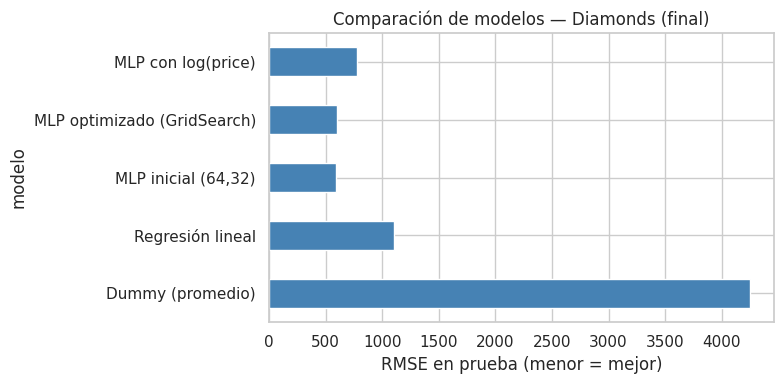

In [ ]:
pd.DataFrame(resultados_diam).set_index("modelo")["RMSE_prueba"].plot(
    kind="barh", figsize=(8, 4), color="steelblue"
)
plt.xlabel("RMSE en prueba (menor = mejor)")
plt.title("Comparación de modelos — Diamonds (final)")
plt.tight_layout()
plt.show()

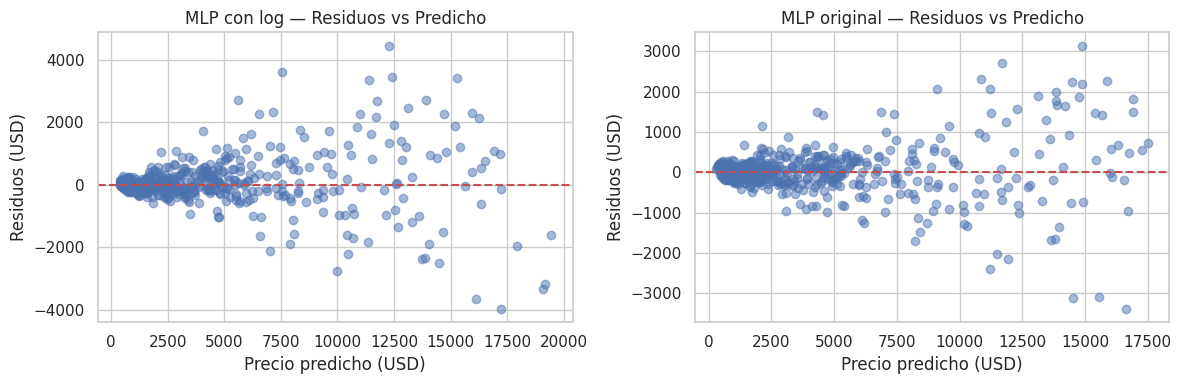

In [ ]:
pred_log = modelo_log.predict(X_test)
residuos_log = y_test - pred_log

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(pred_log, residuos_log, alpha=0.5)
axes[0].axhline(0, color='r', linestyle='--')
axes[0].set_xlabel("Precio predicho (USD)")
axes[0].set_ylabel("Residuos (USD)")
axes[0].set_title("MLP con log — Residuos vs Predicho")

axes[1].scatter(mejor_diam.predict(X_test), y_test - mejor_diam.predict(X_test), alpha=0.5)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel("Precio predicho (USD)")
axes[1].set_ylabel("Residuos (USD)")
axes[1].set_title("MLP del GridSearch (16, — Residuos vs Predicho")

plt.tight_layout()
plt.show()


Contrario a la intuición teórica, aplicar la transformación logarítmica al
target **empeoró el modelo** en todas las métricas:
- RMSE_test pasó de $592 a $774 (+30%)
- R²_test bajó de 0.981 a 0.967
- MAE_test pasó de $332 a $420 (+26%)

**Por qué pasó esto:**

1. **El MLP ya captura la no-linealidad**. La transformación log es útil
   principalmente para modelos lineales que no pueden modelar curvas. Un
   MLP con capas ocultas ya aprende relaciones no lineales por sí mismo.
   Aplicar log encima no agrega información, al contrario, le quita
   flexibilidad al modelo.

2. **El log cambia la métrica de optimización**. Al entrenar con log(y),
   el modelo minimiza errores proporcionales (relativos) en vez de
   absolutos. Esto hace que priorice los diamantes baratos y descuide
   los caros. Pero las métricas finales están en USD, donde esta
   priorización se castiga.

3. **`expm1` amplifica errores exponencialmente**. Un pequeño error en
   escala log se vuelve un error grande en USD una vez revertida la
   transformación.

4. **El RMSE_entrenamiento también subió** (582 → 838), lo que confirma
   que el modelo con log genuinamente aprendió peor, no es solo un
   problema de generalización.




**Decisión final**: el **MLP inicial (64,32) con hiperparámetros default**
es el mejor modelo para este problema, con R²=0.981 y RMSE=$592 en test.

El MLP sí justifica su complejidad frente a la lineal.

El GridSearchCV no mejoró el modelo pero confirmó que es robusto a sus hiperparámetros.

La permutation importance validó que el modelo usa variables coherentes con el dominio.

El log del target empeoró el modelo: lección sobre no aplicar heurísticas sin validar.

---
## Actividad 4 · reflexión final 💭

Respondé brevemente (2-4 líneas cada una) con tus propias palabras:

1. ¿Por qué es **obligatorio** escalar las variables antes de entrenar una red neuronal? ¿Qué observaste en la demostración?
2. ¿Por qué ajustamos hiperparámetros con **validación cruzada sobre el entrenamiento** y no directamente mirando el conjunto de prueba?
3. En el Paso 6 vimos que distintas semillas dan resultados distintos. ¿Cómo influye esto en la forma en que deberíamos **reportar** el rendimiento de una red neuronal?

**Tus respuestas:**

#### 1
Las redes aprenden ajustando pesos paso a paso, y si las variables tienen escalas muy distintas (por ejemplo weight en miles y cylinders entre 3 y 8), los ajustes quedan desbalanceados y el entrenamiento se vuelve inestable. En la demostración, sin escalar el R² iba de 0.89 a −72 según la semilla (a veces peor que predecir el promedio). Con escalado, todas las corridas dieron entre 0.90 y 0.91: resultados buenos y estables.

#### 2

El conjunto de prueba simula datos nuevos que el modelo nunca vio. Si lo usamos para elegir hiperparámetros, terminamos ajustando el modelo a ese conjunto y la métrica final sale optimista, porque ya no es una evaluación independiente. Con validación cruzada elegimos usando solo el train y dejamos el test para una única evaluación final honesta.

#### 3

Como los pesos iniciales son aleatorios, una sola corrida puede dar un resultado bueno o malo por azar. Por eso hay que reportar el rendimiento como promedio y desvío de varias semillas (por ejemplo, 10 corridas), no el mejor valor obtenido. Si la diferencia entre dos modelos es menor que ese desvío, no se puede afirmar que uno sea mejor que el otro.

---
# 🏁 ¡Felicitaciones!

Completaste una introducción completa al uso de redes neuronales en `scikit-learn`. Recordá la idea central:

> **Una red neuronal no es magia: es un modelo más que hay que preparar bien, evaluar con honestidad y comparar contra alternativas simples.**

 📚 Para seguir explorando
- Documentación de redes neuronales en scikit-learn: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>
- Guía de validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Ajuste de hiperparámetros: <https://scikit-learn.org/stable/modules/grid_search.html>
- Importancia por permutación: <https://scikit-learn.org/stable/modules/permutation_importance.html>
- Datasets usados: [Auto MPG (UCI)](https://archive.ics.uci.edu/dataset/9/auto+mpg), [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), y los datasets de ejemplo de [seaborn-data](https://github.com/mwaskom/seaborn-data).